# Mayavi viewer in a hosted notebook

Upload this notebook to a hosted Jupyter site and run the cells in order. The first run installs Mayavi and VTK, which can take a few minutes.

It needs a site with a real Python kernel on a server, such as a JupyterHub, Google Colab, or [Binder](https://mybinder.org).
It cannot work on jupyter.org/try (JupyterLite): there, Python is compiled to WebAssembly and runs in your browser, and VTK has no WebAssembly build. The first code cell detects that case and stops with an explanation.

## 1. Environment check and install

In [1]:
import os
import sys
import platform

print("Python:", sys.version.split()[0], "| platform:", sys.platform, platform.machine())
if sys.platform == "emscripten":
    raise RuntimeError(
        "This is JupyterLite: Python runs in the browser as WebAssembly. "
        "Mayavi needs VTK's native libraries, which have no WebAssembly build, so it cannot run here. "
        "Use a Jupyter site with a server-side kernel instead (Google Colab, mybinder.org, a JupyterHub)."
    )

IN_COLAB = "google.colab" in sys.modules
HEADLESS_LINUX = sys.platform.startswith("linux") and not os.environ.get("DISPLAY")
print("Colab:", IN_COLAB, "| headless Linux:", HEADLESS_LINUX)

Python: 3.12.7 | platform: darwin arm64
Colab: False | headless Linux: False


In [2]:
%pip install -q mayavi vtk ipywidgets ipyevents "puremagic<2"  # puremagic 2 dropped a function Mayavi 4.9.0 uses


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /Users/ethanpollack/projects/claude/mayavi/.venv/bin/python3.12 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
# On a headless Linux server there is no display, so VTK has to render through OSMesa (software OpenGL).
if HEADLESS_LINUX:
    if os.geteuid() == 0:  # Colab runs as root and can install system packages
        !apt-get -qq install -y libosmesa6 > /dev/null
    os.environ["VTK_DEFAULT_OPENGL_WINDOW"] = "vtkOSOpenGLRenderWindow"
    os.environ["ETS_TOOLKIT"] = "null"  # no Qt GUI on the server

if IN_COLAB:  # Colab only shows third-party widgets (ipyevents) with this enabled
    from google.colab import output
    output.enable_custom_widget_manager()

## 2. Setup

In [4]:
import vtk
import mayavi
print("Mayavi:", mayavi.__version__, "| VTK:", vtk.vtkVersion.GetVTKVersion())

import asyncio

import numpy as np
from IPython.display import Image, display
from mayavi import mlab
from mayavi.tools import notebook
from mayavi.tools.remote.ipy_remote import IPyRemoteWidget
from mayavi.tools.remote.remote_scene import ImageEncoder
from tvtk.api import tvtk


def encode_frame(render_window, image_type="png", quality=60, render=True):
    """Return the window's current frame as PNG or JPEG bytes, rendering it first if asked."""
    if render:
        render_window.render()
    w2if = tvtk.WindowToImageFilter(input=render_window, read_front_buffer=False, should_rerender=False)
    if image_type == "png":
        writer = tvtk.PNGWriter(write_to_memory=True)
    else:
        writer = tvtk.JPEGWriter(quality=quality, write_to_memory=True)
    writer.set_input_connection(w2if.output_port)
    writer.write()
    return writer.result.to_array().tobytes()


# Fix 1: Mayavi 4.9.0's frame grabber calls ndarray.tostring() (removed in NumPy 2), and its cached
# pipeline can send a stale frame on mouse release, so the view snaps back. Grab every frame fresh.
# Mayavi calls this right after each render, so reuse that render instead of rendering again.
ImageEncoder.get_raw_image = lambda self: encode_frame(self.scene.render_window, self.image_type, self.quality, render=False)

# Fix 2: Mayavi passes the browser's key name (e.g. "Shift") to VTK as a one-character key code,
# which raises ValueError. Skip named keys. The original is stored once, so re-running this cell is safe.
if not hasattr(IPyRemoteWidget, "_original_handle_ipyevent"):
    IPyRemoteWidget._original_handle_ipyevent = IPyRemoteWidget.handle_ipyevent

def _skip_named_keys(self, event):
    if event["type"] in ("keydown", "keyup") and len(event.get("key", "")) != 1:
        return
    self._original_handle_ipyevent(event)

IPyRemoteWidget.handle_ipyevent = _skip_named_keys

mlab.init_notebook("ipy")  # also switches Mayavi to offscreen rendering

# Fix 3: Mayavi never schedules the throttled last frame of a drag. Run it on the kernel's event loop.
notebook._backend._widget_manager.sm.call_later = (
    lambda secs, f, *args, **kw: asyncio.get_event_loop().call_later(secs, lambda: f(*args, **kw))
)

Mayavi: 4.9.0 | VTK: 9.7.1
Notebook initialized with ipy backend.


## 3. Static render

An image of the scene should appear below the cell. This alone shows Mayavi rendering on the server and displaying in the notebook.

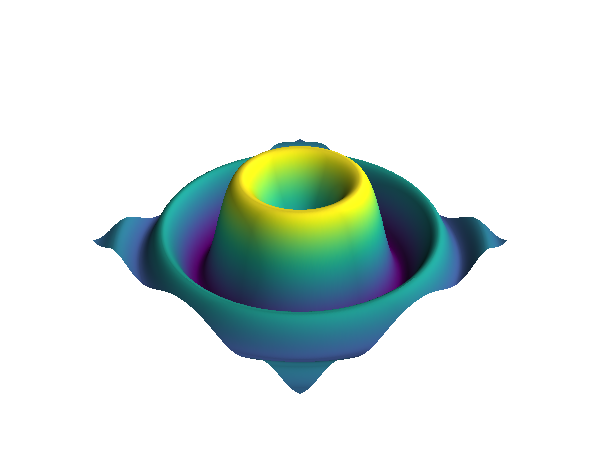

In [5]:
x, y = np.mgrid[-3:3:150j, -3:3:150j]
z = np.sin(x**2 + y**2) * np.exp(-0.2 * (x**2 + y**2))

fig = mlab.figure(bgcolor=(1, 1, 1), size=(600, 450))
mlab.surf(x, y, z, colormap="viridis", warp_scale=2)
display(Image(data=encode_frame(fig.scene.render_window)))
mlab.close(fig)

## 4. Interactive viewer

Drag to rotate, scroll to zoom. Frames are rendered on the server and streamed to your browser.

In [6]:
fig = mlab.figure(bgcolor=(1, 1, 1), size=(600, 450))
mlab.surf(x, y, z, colormap="viridis", warp_scale=2)
mlab.view(azimuth=45, elevation=60, distance="auto")
fig  # displays the interactive viewer

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x02X\x00\x00\x01\xc2\x08\x02\x00\x00\x00\xbc\x11 3\x…

## 5. Self-check

In [7]:
# Simulate a mouse drag on the viewer and confirm a new frame arrives.
viewer = notebook._backend._widget_manager.scene_to_ipy(fig.scene)
before = bytes(viewer.image.value)
assert len(before) > 1000, "viewer has no image"

for key in ("Shift", "Meta", "ArrowLeft"):  # named keys must not raise
    viewer.handle_ipyevent({"type": "keydown", "key": key})
    viewer.handle_ipyevent({"type": "keyup", "key": key})

camera_before = tuple(fig.scene.camera.position)
viewer.handle_ipyevent({"type": "mousedown", "button": 0, "relativeX": 300, "relativeY": 225})
for i in range(1, 31):  # Mayavi only acts on every third mouse move
    viewer.handle_ipyevent({"type": "mousemove", "button": 0, "relativeX": 300 + 4 * i, "relativeY": 225 + i})
viewer.handle_ipyevent({"type": "mouseup", "relativeX": 420, "relativeY": 255})
await asyncio.sleep(1)  # let the frame sent on release flush
assert tuple(fig.scene.camera.position) != camera_before, "drag did not rotate the camera"
assert viewer.image.format == "PNG", "final frame after release should be PNG"
assert bytes(viewer.image.value) != before, "view snapped back after the mouse was released"
print("Interactive viewer OK")

Interactive viewer OK
